# 05_ROCOv2_Unimodal_DenseNet121_Baseline

**Purpose:** Establish one strong, conventional **image-only** baseline
(DenseNet121, multi-label) before the VLM stages. This notebook trains a
model — that is its entire job. It does **not** touch text, does not build
a Calibration split, and does not implement VLM / conformal / XAI / trust
score components.

### What this notebook does NOT do
- No captions, CUIs-as-text, text encoders, or multimodal fusion — image
  tensor in, 18 logits out.
- No VLM, no VLM training, no conformal prediction, no counterfactual/XAI,
  no trust score. Those belong to later notebooks (06 onward).
- No new dataset split, no Calibration split, no modification of Notebooks
  01–04 or the original ROCOv2 files.
- No use of Test for anything except the single, final, frozen evaluation.

### Inputs (read-only)
- `Prepared/train_prepared.csv`, `validation_prepared.csv`, `test_prepared.csv`,
  `label_mapping.json` — from `02_ROCOv2_Dataset_Preparation.ipynb`.
- `Prepared/Preprocessing/preprocessing_config.json` — from
  `04_ROCOv2_Preprocessing_Pipeline.ipynb` (target image size, Train-only
  channel normalization statistics, augmentation policy). Values are read
  from this file, never re-derived or re-guessed here.
- Original ROCOv2 image ZIPs (read-only).

### Outputs
All 18 artifacts specified by the research task, under
`Prepared/Baselines/DenseNet121_Unimodal/` (config, training history,
validation/test/per-label metrics, predictions, both checkpoints,
publication-quality learning-curve/ROC/PR/confusion-matrix figures as
vector PDF + 300 DPI PNG, `reproducibility.json`, `artifact_manifest.json`).

### Split roles (unchanged from the authoritative 02/03/04 protocol)
- **Train** — model training and every statistic fit in this notebook
  (class-imbalance weighting, normalization already fixed by 04).
- **Validation** — early stopping, checkpoint selection, development
  decisions only. **Not** treated as a Calibration set (see the explicit
  warning near the end of this notebook).
- **Test** — loaded once, at the very end, for final evaluation only. Never
  used to pick epochs, checkpoints, hyperparameters, architecture, or a
  decision threshold.

### Naming note
This is notebook **05** in the actual on-disk sequence
(01 EDA+Audit → 02 Dataset Preparation → 03 Split Integrity Audit →
04 Preprocessing Pipeline → **05 this notebook**), continuing after the
already-completed preprocessing stage rather than reusing its number.


In [32]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import os
import io
import sys
import json
import time
import random
import shutil
import zipfile
import warnings
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

# ------------------------------------------------------------
# Explicit project paths (no hard-coded temp paths)
# ------------------------------------------------------------
ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"
PREPROCESSING_DIR = PREPARED_DIR / "Preprocessing"

# ------------------------------------------------------------
# MULTI-SEED EXPERIMENT -- output directory for this run.
# Original single-seed (reference) value, DO NOT reuse for a new seed run:
#   BASELINE_DIR = PREPARED_DIR / "Baselines" / "DenseNet121_Unimodal"
# Active configuration for THIS run (must match SEED below):
#   Seed 123  -> DenseNet121_Unimodal_seed123
#   Seed 2024 -> DenseNet121_Unimodal_seed2024
#   Seed 3407 -> DenseNet121_Unimodal_seed3407
#   Seed 7777 -> DenseNet121_Unimodal_seed7777
# ------------------------------------------------------------
BASELINE_DIR = PREPARED_DIR / "Baselines" / "DenseNet121_Unimodal_seed2024"
CKPT_DIR = BASELINE_DIR / "checkpoints"
FIG_DIR = BASELINE_DIR / "figures"
for d in [BASELINE_DIR, CKPT_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Inputs (read-only)
TRAIN_PREPARED_PATH = PREPARED_DIR / "train_prepared.csv"
VALID_PREPARED_PATH = PREPARED_DIR / "validation_prepared.csv"
TEST_PREPARED_PATH = PREPARED_DIR / "test_prepared.csv"
LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"
PREPROCESSING_CONFIG_PATH = PREPROCESSING_DIR / "preprocessing_config.json"

IMAGE_ZIP_FILES = {
    "train": ROCO_ROOT / "Train" / "Images" / "train_images.zip",
    "validation": ROCO_ROOT / "Validation" / "Images" / "valid_images.zip",
    "test": ROCO_ROOT / "Test" / "Images" / "test_images.zip",
}

# Outputs — the 18 artifacts required by the research task (Part 22)
CONFIG_PATH = BASELINE_DIR / "densenet121_config.json"
HISTORY_PATH = BASELINE_DIR / "densenet121_training_history.csv"
VAL_METRICS_PATH = BASELINE_DIR / "densenet121_validation_metrics.csv"
TEST_METRICS_PATH = BASELINE_DIR / "densenet121_test_metrics.csv"
PER_LABEL_METRICS_PATH = BASELINE_DIR / "densenet121_per_label_metrics.csv"
PREDICTIONS_PATH = BASELINE_DIR / "densenet121_predictions.csv"
BEST_MODEL_PATH = CKPT_DIR / "densenet121_best_model.pt"
LAST_MODEL_PATH = CKPT_DIR / "densenet121_last_model.pt"
LEARNING_CURVES_PDF = FIG_DIR / "learning_curves.pdf"
LEARNING_CURVES_PNG = FIG_DIR / "learning_curves_300dpi.png"
ROC_CURVES_PDF = FIG_DIR / "roc_curves.pdf"
ROC_CURVES_PNG = FIG_DIR / "roc_curves_300dpi.png"
PR_CURVES_PDF = FIG_DIR / "precision_recall_curves.pdf"
PR_CURVES_PNG = FIG_DIR / "precision_recall_curves_300dpi.png"
CM_PDF = FIG_DIR / "multilabel_confusion_matrices.pdf"
CM_PNG = FIG_DIR / "multilabel_confusion_matrices_300dpi.png"
REPRODUCIBILITY_PATH = BASELINE_DIR / "reproducibility.json"
MANIFEST_PATH = BASELINE_DIR / "artifact_manifest.json"

# Supplementary (not one of the 18 required artifacts) — a transparent,
# append-only log of any sample that could not be read even after the zip
# fallback, so a skip is always visible and never silent.
CORRUPT_SAMPLE_LOG_PATH = BASELINE_DIR / "corrupt_samples_skipped_during_training.jsonl"

# Authoritative-artifact overwrite protection (matches the convention already
# established by 02's label_mapping.json / 04's preprocessing_config.json).
ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
# ------------------------------------------------------------
# MULTI-SEED EXPERIMENT -- active seed for this run.
# Original single-seed (reference) value, DO NOT reuse for a new seed run: SEED = 42
# Must match the BASELINE_DIR suffix set above. Seed/directory pairs for
# this experiment: 123, 2024, 3407, 7777 (42 is the existing reference,
# retrained only if explicitly decided later -- see MULTISEED_EXPERIMENT_PLAN.md).
# ------------------------------------------------------------
SEED = 2024

def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed(seed)
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

set_global_seed(SEED)

print("=" * 80)
print("NOTEBOOK 05 — UNIMODAL DENSENET121 BASELINE")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("BASELINE_DIR:", BASELINE_DIR)
print("Random seed:", SEED)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive available.
NOTEBOOK 05 — UNIMODAL DENSENET121 BASELINE
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
BASELINE_DIR: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed2024
Random seed: 2024


## 1. Verify required inputs from Notebooks 02 and 04

Hard-required. This notebook does not fabricate a substitute for anything
missing — it stops.

In [33]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "train_prepared.csv": TRAIN_PREPARED_PATH,
    "validation_prepared.csv": VALID_PREPARED_PATH,
    "test_prepared.csv": TEST_PREPARED_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
    "preprocessing_config.json": PREPROCESSING_CONFIG_PATH,
}

missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]

if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 05 input artifacts are missing:\n\n"
        + "\n".join(missing_inputs)
        + "\n\nRun 02_ROCOv2_Dataset_Preparation.ipynb and "
        "04_ROCOv2_Preprocessing_Pipeline.ipynb first."
    )

for name, path in IMAGE_ZIP_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Original image ZIP missing for {name}: {path}")

print("PASS — Required Notebook 02/04 artifacts and original image ZIPs exist.")
for name, path in required_inputs.items():
    print(f"{name:30s}: {path}")


PASS — Required Notebook 02/04 artifacts and original image ZIPs exist.
train_prepared.csv            : /content/drive/MyDrive/ROCOv2/Prepared/train_prepared.csv
validation_prepared.csv       : /content/drive/MyDrive/ROCOv2/Prepared/validation_prepared.csv
test_prepared.csv             : /content/drive/MyDrive/ROCOv2/Prepared/test_prepared.csv
label_mapping.json            : /content/drive/MyDrive/ROCOv2/Prepared/label_mapping.json
preprocessing_config.json     : /content/drive/MyDrive/ROCOv2/Prepared/Preprocessing/preprocessing_config.json


## 2. Load the authoritative split, label taxonomy, and preprocessing config

Split sizes, label order, and image preprocessing values are all **read
from disk**, never hardcoded or re-derived independently. The counts you
reported (Train=59,958 / Validation=9,904 / Test=9,927) are compared
against what is actually on disk for information only — this notebook
trusts the files, not a remembered number.

In [34]:
# ============================================================
# CELL 3 — LOAD SPLITS, LABEL MAPPING, PREPROCESSING CONFIG
# ============================================================

split_dfs = {
    "train": pd.read_csv(TRAIN_PREPARED_PATH),
    "validation": pd.read_csv(VALID_PREPARED_PATH),
    "test": pd.read_csv(TEST_PREPARED_PATH),
}

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)

assert len(label_mapping) == 18, "Authoritative label_mapping.json must contain exactly 18 labels."

LABEL_COLUMNS = [f"label_{cui}" for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
N_LABELS = len(LABEL_COLUMNS)

for split_name, df in split_dfs.items():
    missing_cols = set(LABEL_COLUMNS) - set(df.columns)
    if missing_cols:
        raise ValueError(f"{split_name}: missing label columns {sorted(missing_cols)}")

with open(PREPROCESSING_CONFIG_PATH, "r", encoding="utf-8") as f:
    preprocessing_config = json.load(f)

IMAGE_SIZE = preprocessing_config["image"]["target_image_size"]
CHANNEL_MEAN = preprocessing_config["image"]["channel_mean"]
CHANNEL_STD = preprocessing_config["image"]["channel_std"]

CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen", "C0002978": "Angiogram", "C0006141": "Breast",
    "C0023216": "Lower Extremity", "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis", "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium", "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography", "C0041618": "Ultrasonography",
    "C0205106": "Transverse", "C0205129": "Sagittal", "C0817096": "Chest",
    "C1140618": "Upper Extremity", "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior", "C1999039": "Anterior-Posterior",
}
LABEL_NAMES = [
    CANONICAL_LABEL_NAMES.get(cui, cui)
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]

reported_counts = {"train": 59958, "validation": 9904, "test": 9927}

print("=" * 80)
print("AUTHORITATIVE SPLIT (from disk)")
print("=" * 80)
for split_name, df in split_dfs.items():
    on_disk = len(df)
    reported = reported_counts[split_name]
    flag = "MATCHES" if on_disk == reported else "DIFFERS FROM reported value — trusting the file, not the report"
    print(f"{split_name.capitalize():12s}: on-disk={on_disk:,}  reported={reported:,}  [{flag}]")

print(f"\nIMAGE_SIZE (from preprocessing_config.json): {IMAGE_SIZE}")
print(f"CHANNEL_MEAN: {CHANNEL_MEAN}")
print(f"CHANNEL_STD:  {CHANNEL_STD}")
print(f"\nLabel taxonomy ({N_LABELS} labels):")
for i, (col, name) in enumerate(zip(LABEL_COLUMNS, LABEL_NAMES)):
    print(f"  {i:02d} | {col} | {name}")


AUTHORITATIVE SPLIT (from disk)
Train       : on-disk=59,666  reported=59,958  [DIFFERS FROM reported value — trusting the file, not the report]
Validation  : on-disk=9,819  reported=9,904  [DIFFERS FROM reported value — trusting the file, not the report]
Test        : on-disk=9,870  reported=9,927  [DIFFERS FROM reported value — trusting the file, not the report]

IMAGE_SIZE (from preprocessing_config.json): 224
CHANNEL_MEAN: [0.3411375121788792, 0.3471113800019527, 0.34902790001484524]
CHANNEL_STD:  [0.29433716104150287, 0.2970567979066339, 0.29809280909672176]

Label taxonomy (18 labels):
  00 | label_C0000726 | Abdomen
  01 | label_C0002978 | Angiogram
  02 | label_C0006141 | Breast
  03 | label_C0023216 | Lower Extremity
  04 | label_C0024485 | Magnetic Resonance Imaging
  05 | label_C0030797 | Pelvis
  06 | label_C0032743 | Positron-Emission Tomography
  07 | label_C0037303 | Bone structure of cranium
  08 | label_C0037949 | Vertebral column
  09 | label_C0040405 | X-Ray Computed

## 3. Training configuration (single source of truth)

Every hyperparameter used anywhere in this notebook is declared here, once
— nothing is scattered as an unexplained magic number in later cells.

In [35]:
# ============================================================
# CELL 4 — TRAINING CONFIGURATION (Part 9 — single configuration block)
# ============================================================

TRAINING_CONFIG = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": 32,
    "num_workers": 2,
    "pin_memory": True,
    "stage1_max_epochs": 5,
    "stage1_lr": 1e-3,
    "stage2_max_epochs": 30,
    "stage2_lr": 1e-5,
    "optimizer": "AdamW",
    "weight_decay": 1e-4,
    "scheduler": "ReduceLROnPlateau(mode='max', factor=0.5, patience=2, on=validation_macro_f1)",
    "min_lr": 1e-7,
    "early_stopping_metric": "validation_macro_f1",
    "early_stopping_patience": 7,
    "gradient_clip_norm": 1.0,
    "mixed_precision": "auto (torch.cuda.amp if CUDA available, else disabled)",
    "loss": "BCEWithLogitsLoss(pos_weight=train-only, capped)",
    "pos_weight_cap": 20.0,
    "decision_threshold": 0.5,
    "threshold_strategy": (
        "Fixed at 0.5, applied identically to Validation and Test. No "
        "threshold optimization is performed in this notebook (Part 13 "
        "permits 0.5 as the primary reporting threshold; optimizing it "
        "would require Validation-only tuning, deliberately out of scope "
        "here to keep Test fully untouched until the single final "
        "evaluation)."
    ),
    "checkpoint_dir": str(CKPT_DIR),
}

print("=" * 80)
print("TRAINING CONFIGURATION")
print("=" * 80)
for k, v in TRAINING_CONFIG.items():
    print(f"{k:28s}: {v}")


TRAINING CONFIGURATION
seed                        : 2024
image_size                  : 224
batch_size                  : 32
num_workers                 : 2
pin_memory                  : True
stage1_max_epochs           : 5
stage1_lr                   : 0.001
stage2_max_epochs           : 30
stage2_lr                   : 1e-05
optimizer                   : AdamW
weight_decay                : 0.0001
scheduler                   : ReduceLROnPlateau(mode='max', factor=0.5, patience=2, on=validation_macro_f1)
min_lr                      : 1e-07
early_stopping_metric       : validation_macro_f1
early_stopping_patience     : 7
gradient_clip_norm          : 1.0
mixed_precision             : auto (torch.cuda.amp if CUDA available, else disabled)
loss                        : BCEWithLogitsLoss(pos_weight=train-only, capped)
pos_weight_cap              : 20.0
decision_threshold          : 0.5
threshold_strategy          : Fixed at 0.5, applied identically to Validation and Test. No threshold opti

## 3b. Extract source ZIPs to plain local files (root-cause fix)

Two prior workarounds were tried and ruled out by evidence:

1. **Corrupted archive?** `zipfile.ZipFile(...).testzip()` — which opens
   and fully decompresses *every* member — found **zero** bad entries via
   a single sequential read. The bytes on disk are fine.
2. **Google Drive FUSE-mount concurrency?** Copying the ZIP to local Colab
   disk and reading DataLoader batches from that local copy produced the
   **same** volume of `BadZipFile`/`zlib.error` failures. Storage medium
   was not the variable.

What's common to every clean run (`testzip()`, the original Notebook 04
audit) is **sequential, in-order** access through one `ZipFile` instance.
What's common to every failing run is **shuffled, random-offset** access
through fresh `ZipFile` instances in separate DataLoader worker processes.
That pattern points to CPython zipfile's overlapped-entries safety check
itself: it appears to build its internal validity state incrementally as
entries are opened, so a "cold" instance hit with out-of-order access can
trip a false positive that then poisons *that instance's* state —
cascading into spurious `BadZipFile`/CRC/decompression errors on other,
perfectly valid entries read afterward through the same instance. This
would explain the volume, the variety of error messages, and why order is
the deciding factor rather than the file or the storage medium.

**Root-cause fix:** stop parsing ZIP structure at read time entirely.
Extract every image to a plain file once — a sequential operation, the one
access pattern that has been reliable in every test — then read plain
files during training. No ZIP parsing, no incremental internal state, no
order sensitivity left to trip.

In [36]:
# ============================================================
# CELL 4B — EXTRACT SOURCE ZIPS TO PLAIN LOCAL FILES (root-cause fix)
# ============================================================

LOCAL_IMAGE_DIR = Path("/content/rocov2_images_local")
LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

EXTRACTED_IMAGE_DIRS = {
    split_name: LOCAL_IMAGE_DIR / f"{split_name}_extracted"
    for split_name in IMAGE_ZIP_FILES
}

def _extract_if_needed(zip_path, extract_dir, expected_members):
    extract_dir.mkdir(parents=True, exist_ok=True)
    existing = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if existing >= len(expected_members):
        print(f"Already extracted, skipping: {extract_dir} "
              f"({existing:,} files present)")
        return
    print(f"Extracting {zip_path.name} -> {extract_dir} "
          f"({len(expected_members):,} members, sequential read)...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)
    extracted = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if extracted != len(expected_members):
        raise IOError(
            f"Extraction count mismatch for {zip_path.name}: "
            f"expected {len(expected_members):,} members, found {extracted:,} "
            f"files under {extract_dir}."
        )
    print(f"  done: {extracted:,} files extracted.")

for split_name, drive_path in IMAGE_ZIP_FILES.items():
    with zipfile.ZipFile(drive_path, "r") as _zf:
        _members = [n for n in _zf.namelist() if not n.endswith("/")]
    _extract_if_needed(drive_path, EXTRACTED_IMAGE_DIRS[split_name], _members)

print("\nEXTRACTED_IMAGE_DIRS:")
for split_name, path in EXTRACTED_IMAGE_DIRS.items():
    print(f"  {split_name:12s}: {path}")


Already extracted, skipping: /content/rocov2_images_local/train_extracted (59,958 files present)
Already extracted, skipping: /content/rocov2_images_local/validation_extracted (9,904 files present)
Already extracted, skipping: /content/rocov2_images_local/test_extracted (9,927 files present)

EXTRACTED_IMAGE_DIRS:
  train       : /content/rocov2_images_local/train_extracted
  validation  : /content/rocov2_images_local/validation_extracted
  test        : /content/rocov2_images_local/test_extracted


## 4. Local image reader (plain files — no ZIP parsing at read time)

Reads `Image_Member`-relative paths directly from the extracted directory.
No `zipfile` module involvement during training, so none of the
order-dependent ZIP-parsing failure modes above can occur here.

In [37]:
# ============================================================
# CELL 5 — LOCAL IMAGE READER (plain files, no ZIP parsing)
# ============================================================

class LocalImageReader:
    def __init__(self, extract_dir):
        self.extract_dir = Path(extract_dir)

    def read_bytes(self, member):
        path = self.extract_dir / member
        return path.read_bytes()


zip_readers = {
    split_name: LocalImageReader(EXTRACTED_IMAGE_DIRS[split_name])
    for split_name in IMAGE_ZIP_FILES
}

for split_name, df in split_dfs.items():
    sample_row = df.iloc[0]
    raw_bytes = zip_readers[split_name].read_bytes(sample_row["Image_Member"])
    assert len(raw_bytes) > 0, f"{split_name}: read zero bytes for {sample_row['Image_Member']}"

print("PASS — Local image reader verified on one sample per split.")


PASS — Local image reader verified on one sample per split.


## 5. Image-only Dataset (Part 2 — image in, 18-dim multi-hot label out)

No caption, CUI string, or text field is read by `__getitem__`. Each item
is exactly `(image_tensor, label_vector, sample_id)`.

Given the archive already exhibits multiple real corruption modes (Cell 4),
a sample that fails even after the `unzip` fallback is **not** allowed to
crash a multi-hour training run: `__getitem__` retries with a different
random index (bounded), but every such skip is appended to
`corrupt_samples_skipped_during_training.jsonl` and printed — never
silently dropped. That log is read back and reported in the final summary
(Cell 29).

In [38]:
# ============================================================
# CELL 6 — IMAGE-ONLY MULTI-LABEL DATASET (retry-and-log on unreadable samples)
# ============================================================

try:
    from PIL import Image
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow"], check=True)
    from PIL import Image

import torch
from torch.utils.data import Dataset

def _append_corrupt_sample_log(log_path, record):
    with open(log_path, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, default=str) + "\n")

class ROCOv2ImageOnlyDataset(Dataset):
    def __init__(self, df, split_name, zip_reader, transform, label_columns,
                 corrupt_log_path, max_retries=5):
        self.df = df.reset_index(drop=True)
        self.split_name = split_name
        self.zip_reader = zip_reader
        self.transform = transform
        self.label_columns = label_columns
        self.corrupt_log_path = corrupt_log_path
        self.max_retries = max_retries

    def __len__(self):
        return len(self.df)

    def _load_item(self, idx):
        row = self.df.iloc[idx]
        raw_bytes = self.zip_reader.read_bytes(row["Image_Member"])
        with Image.open(io.BytesIO(raw_bytes)) as img:
            image = self.transform(img.convert("RGB"))
        labels = torch.tensor(
            row[self.label_columns].to_numpy(dtype=np.float32), dtype=torch.float32
        )
        return image, labels, row["ID"]

    def __getitem__(self, idx):
        tried_idx = idx
        last_exc = None
        for attempt in range(self.max_retries + 1):
            try:
                return self._load_item(tried_idx)
            except Exception as exc:
                last_exc = exc
                bad_id = self.df.iloc[tried_idx]["ID"]
                bad_member = self.df.iloc[tried_idx]["Image_Member"]
                print(f"WARNING — [{self.split_name}] unreadable sample skipped: "
                      f"ID={bad_id} ({type(exc).__name__}: {exc}). "
                      f"Substituting a different sample (attempt {attempt + 1}/{self.max_retries}).")
                _append_corrupt_sample_log(self.corrupt_log_path, {
                    "Split": self.split_name, "ID": str(bad_id), "Image_Member": bad_member,
                    "Error": f"{type(exc).__name__}: {exc}", "Timestamp": time.time(),
                })
                tried_idx = random.randrange(len(self.df))
        raise RuntimeError(
            f"[{self.split_name}] Exceeded max_retries={self.max_retries} while searching "
            f"for a readable sample near index {idx}. Last error: "
            f"{type(last_exc).__name__}: {last_exc}"
        )

print("ROCOv2ImageOnlyDataset defined — image + 18-d multi-hot label only, no text.")
print("Unreadable samples: retried with a different sample, always logged, never silent.")


ROCOv2ImageOnlyDataset defined — image + 18-d multi-hot label only, no text.
Unreadable samples: retried with a different sample, always logged, never silent.


## 6. Image transforms (reusing Notebook 04's frozen policy — not redefined)

`IMAGE_SIZE`, `CHANNEL_MEAN`, `CHANNEL_STD`, and the augmentation policy are
all read from `preprocessing_config.json`. Train uses the approved
augmentation (mild rotation + color jitter, **flips intentionally
disabled** because the label taxonomy encodes imaging orientation).
Validation and Test use a purely deterministic transform — no random
augmentation is ever applied to them.

In [39]:
# ============================================================
# CELL 7 — IMAGE TRANSFORMS (values sourced from preprocessing_config.json)
# ============================================================

import torchvision.transforms as T

_configured_train_aug = preprocessing_config["image"].get("train_augmentation", [])
_flip_reason = preprocessing_config["image"].get("flip_augmentation_disabled_reason", "")
print("Notebook 04's recorded train augmentation policy:", _configured_train_aug)
print("Flip-disabled rationale (carried forward unchanged):", _flip_reason)

train_transform = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=CHANNEL_MEAN, std=CHANNEL_STD),
])

eval_transform = T.Compose([
    T.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=CHANNEL_MEAN, std=CHANNEL_STD),
])

image_transforms = {"train": train_transform, "validation": eval_transform, "test": eval_transform}

print("\nTrain transform (augmented):\n", train_transform)
print("\nValidation/Test transform (deterministic):\n", eval_transform)


Notebook 04's recorded train augmentation policy: ['RandomRotation(10)', 'ColorJitter(0.1, 0.1)']
Flip-disabled rationale (carried forward unchanged): Label taxonomy encodes imaging orientation (Postero-Anterior / Anterior-Posterior / Transverse / Sagittal).

Train transform (augmented):
 Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.9, 1.1), contrast=(0.9, 1.1), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.3411375121788792, 0.3471113800019527, 0.34902790001484524], std=[0.29433716104150287, 0.2970567979066339, 0.29809280909672176])
)

Validation/Test transform (deterministic):
 Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.3411375121788792, 0.3471113800019527, 0.34902790001484524], std=[0.29433716104150287, 0.297056797906633

## 7. Class imbalance analysis — Train only (Part 7)

Positive count, negative count, prevalence, and imbalance ratio for every
label, computed **exclusively from Train**. Never from Validation or Test.

In [40]:
# ============================================================
# CELL 8 — CLASS IMBALANCE ANALYSIS (TRAIN ONLY)
# ============================================================

train_label_matrix = split_dfs["train"][LABEL_COLUMNS].to_numpy(dtype=np.float64)
n_train = train_label_matrix.shape[0]

pos_counts = train_label_matrix.sum(axis=0)
neg_counts = n_train - pos_counts
prevalence = pos_counts / n_train
imbalance_ratio = neg_counts / np.clip(pos_counts, 1, None)  # neg:pos ratio

class_balance_df = pd.DataFrame({
    "Label_Column": LABEL_COLUMNS,
    "Label_Name": LABEL_NAMES,
    "Positive_Count_Train": pos_counts.astype(int),
    "Negative_Count_Train": neg_counts.astype(int),
    "Prevalence_Train": prevalence,
    "Imbalance_Ratio_Neg_to_Pos": imbalance_ratio,
}).sort_values("Positive_Count_Train", ascending=False).reset_index(drop=True)

display(class_balance_df)

print(
    "\nFormula: prevalence = positive_count / n_train; "
    "imbalance_ratio = negative_count / positive_count "
    "(both computed on TRAIN only, per label)."
)


,Label_Column,Label_Name,Positive_Count_Train,Negative_Count_Train,Prevalence_Train,Imbalance_Ratio_Neg_to_Pos
0,label_C0040405,X-Ray Computed Tomography,20495,39171,0.343495,1.911247
1,label_C1306645,Plain x-ray,16604,43062,0.278282,2.593471
2,label_C0024485,Magnetic Resonance Imaging,9796,49870,0.164181,5.090853
3,label_C0041618,Ultrasonography,8306,51360,0.139208,6.183482
4,label_C0817096,Chest,7508,52158,0.125834,6.946990
5,label_C1999039,Anterior-Posterior,7111,52555,0.119180,7.390662
6,label_C0002978,Angiogram,3958,55708,0.066336,14.074785
7,label_C1996865,Postero-Anterior,3393,56273,0.056867,16.585028
8,label_C0037303,Bone structure of cranium,3326,56340,0.055744,16.939266
9,label_C0000726,Abdomen,3176,56490,0.053230,17.786524



Formula: prevalence = positive_count / n_train; imbalance_ratio = negative_count / positive_count (both computed on TRAIN only, per label).


## 8. Positive class weighting for BCEWithLogitsLoss (Part 7/8)

`pos_weight[c] = negative_count[c] / positive_count[c]`, computed on
**Train only**, capped at `TRAINING_CONFIG["pos_weight_cap"]` to avoid
destabilizing gradients for extremely rare labels. This is documented
explicitly rather than left as an unexplained tensor.

In [41]:
# ============================================================
# CELL 9 — TRAIN-ONLY POSITIVE CLASS WEIGHTS
# ============================================================

import torch.nn as nn

raw_pos_weight = neg_counts / np.clip(pos_counts, 1, None)
capped_pos_weight = np.clip(raw_pos_weight, a_min=None, a_max=TRAINING_CONFIG["pos_weight_cap"])
n_capped = int((raw_pos_weight > TRAINING_CONFIG["pos_weight_cap"]).sum())

pos_weight_tensor = torch.tensor(capped_pos_weight, dtype=torch.float32)

print(f"pos_weight formula: negative_count / positive_count (Train only), "
      f"capped at {TRAINING_CONFIG['pos_weight_cap']}")
print(f"Labels requiring the cap: {n_capped} / {N_LABELS}")

pos_weight_df = pd.DataFrame({
    "Label_Column": LABEL_COLUMNS,
    "Raw_Pos_Weight": raw_pos_weight,
    "Capped_Pos_Weight": capped_pos_weight,
})
display(pos_weight_df)


pos_weight formula: negative_count / positive_count (Train only), capped at 20.0
Labels requiring the cap: 8 / 18


,Label_Column,Raw_Pos_Weight,Capped_Pos_Weight
0,label_C0000726,17.786524,17.786524
1,label_C0002978,14.074785,14.074785
2,label_C0006141,454.465649,20.000000
3,label_C0023216,24.541952,20.000000
4,label_C0024485,5.090853,5.090853
5,label_C0030797,21.296712,20.000000
6,label_C0032743,115.535156,20.000000
7,label_C0037303,16.939266,16.939266
8,label_C0037949,45.324534,20.000000
9,label_C0040405,1.911247,1.911247


## 9. Datasets and DataLoaders

Train shuffles with a seeded generator; Validation and Test never shuffle.

In [42]:
# ============================================================
# CELL 10 — DATASETS AND DATALOADERS
# ============================================================

from torch.utils.data import DataLoader

datasets = {
    split_name: ROCOv2ImageOnlyDataset(
        df=split_dfs[split_name],
        split_name=split_name,
        zip_reader=zip_readers[split_name],
        transform=image_transforms[split_name],
        label_columns=LABEL_COLUMNS,
        corrupt_log_path=CORRUPT_SAMPLE_LOG_PATH,
    )
    for split_name in ["train", "validation", "test"]
}

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

dataloaders = {
    "train": DataLoader(
        datasets["train"], batch_size=TRAINING_CONFIG["batch_size"], shuffle=True,
        num_workers=TRAINING_CONFIG["num_workers"], pin_memory=TRAINING_CONFIG["pin_memory"],
        worker_init_fn=seed_worker, generator=train_generator, drop_last=False,
    ),
    "validation": DataLoader(
        datasets["validation"], batch_size=TRAINING_CONFIG["batch_size"], shuffle=False,
        num_workers=TRAINING_CONFIG["num_workers"], pin_memory=TRAINING_CONFIG["pin_memory"],
        worker_init_fn=seed_worker, drop_last=False,
    ),
    "test": DataLoader(
        datasets["test"], batch_size=TRAINING_CONFIG["batch_size"], shuffle=False,
        num_workers=TRAINING_CONFIG["num_workers"], pin_memory=TRAINING_CONFIG["pin_memory"],
        worker_init_fn=seed_worker, drop_last=False,
    ),
}

for split_name, dl in dataloaders.items():
    print(f"{split_name.capitalize():12s}: {len(datasets[split_name]):,} samples, {len(dl):,} batches")


Train       : 59,666 samples, 1,865 batches
Validation  : 9,819 samples, 307 batches
Test        : 9,870 samples, 309 batches


## 10. DenseNet121 architecture (Part 3)

Pretrained ImageNet weights (no existing project methodology specifies
otherwise). The original 1000-way ImageNet classifier is replaced with an
18-output linear head — 18 raw logits, no softmax anywhere. `BCEWithLogitsLoss`
is used precisely because this is multi-label, not single-label multiclass.

In [43]:
# ============================================================
# CELL 11 — DENSENET121 MODEL DEFINITION
# ============================================================

import torchvision.models as tv_models

try:
    _weights_enum = tv_models.DenseNet121_Weights.IMAGENET1K_V1
    densenet = tv_models.densenet121(weights=_weights_enum)
    PRETRAINED = True
    PRETRAINED_WEIGHTS_NAME = str(_weights_enum)
except Exception as exc:
    raise RuntimeError(
        "Could not load pretrained ImageNet DenseNet121 weights. Per project "
        "methodology, pretrained weights are preferred unless explicitly "
        "specified otherwise — this notebook does not silently fall back to "
        f"random initialization.\nUnderlying error: {type(exc).__name__}: {exc}"
    )

in_features = densenet.classifier.in_features  # 1024 for DenseNet121

# Explicit initialization of the new head (Kaiming for the linear weight,
# zero bias) — documented rather than left as PyTorch's implicit default.
new_classifier = nn.Linear(in_features, N_LABELS)
nn.init.kaiming_normal_(new_classifier.weight, nonlinearity="linear")
nn.init.zeros_(new_classifier.bias)
densenet.classifier = new_classifier

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
densenet = densenet.to(device)

total_params = sum(p.numel() for p in densenet.parameters())
trainable_params = sum(p.numel() for p in densenet.parameters() if p.requires_grad)

ARCHITECTURE_INFO = {
    "architecture": "DenseNet121",
    "pretrained": PRETRAINED,
    "pretrained_weights": PRETRAINED_WEIGHTS_NAME,
    "input_size": IMAGE_SIZE,
    "classifier_replacement": f"nn.Linear({in_features}, {N_LABELS})",
    "classifier_init": "kaiming_normal_(weight, nonlinearity='linear'); zeros_(bias)",
    "total_parameters": int(total_params),
    "trainable_parameters_at_init": int(trainable_params),
    "device": str(device),
}

print("=" * 80)
print("DENSENET121 ARCHITECTURE")
print("=" * 80)
for k, v in ARCHITECTURE_INFO.items():
    print(f"{k:28s}: {v}")
print("\nImage -> DenseNet121 backbone -> 18 logits -> (eval-time) sigmoid -> 18 probabilities")
print("Loss: BCEWithLogitsLoss(pos_weight=...). No softmax anywhere in this notebook.")


DENSENET121 ARCHITECTURE
architecture                : DenseNet121
pretrained                  : True
pretrained_weights          : DenseNet121_Weights.IMAGENET1K_V1
input_size                  : 224
classifier_replacement      : nn.Linear(1024, 18)
classifier_init             : kaiming_normal_(weight, nonlinearity='linear'); zeros_(bias)
total_parameters            : 6972306
trainable_parameters_at_init: 6972306
device                      : cuda

Image -> DenseNet121 backbone -> 18 logits -> (eval-time) sigmoid -> 18 probabilities
Loss: BCEWithLogitsLoss(pos_weight=...). No softmax anywhere in this notebook.


## 11. Transfer-learning strategy (Part 10)

Two-stage, reproducible strategy — no existing project methodology
specifies an alternative, so this is the strategy used:

- **Stage 1** (head warmup): freeze the DenseNet121 backbone (`features`),
  train only the new 18-way classifier head at a higher learning rate.
- **Stage 2** (fine-tune): unfreeze the entire backbone, continue training
  at a substantially lower learning rate.

Frozen/unfrozen layers, learning rates, and epoch ranges are recorded
explicitly below and saved into `densenet121_config.json`.

In [44]:
# ============================================================
# CELL 12 — TRANSFER-LEARNING STAGE CONTROL
# ============================================================

def set_backbone_trainable(model, trainable):
    for param in model.features.parameters():
        param.requires_grad = trainable
    # classifier head always trainable
    for param in model.classifier.parameters():
        param.requires_grad = True

def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

TRANSFER_LEARNING_PLAN = {
    "stage_1": {
        "description": "Backbone frozen; only the new classifier head trains.",
        "frozen_layers": "densenet.features.*",
        "unfrozen_layers": "densenet.classifier.*",
        "learning_rate": TRAINING_CONFIG["stage1_lr"],
        "max_epochs": TRAINING_CONFIG["stage1_max_epochs"],
    },
    "stage_2": {
        "description": "Entire backbone unfrozen and fine-tuned at a lower learning rate.",
        "frozen_layers": "none",
        "unfrozen_layers": "densenet.features.* and densenet.classifier.*",
        "learning_rate": TRAINING_CONFIG["stage2_lr"],
        "max_epochs": TRAINING_CONFIG["stage2_max_epochs"],
    },
}

print("Transfer-learning plan:")
print(json.dumps(TRANSFER_LEARNING_PLAN, indent=2))


Transfer-learning plan:
{
  "stage_1": {
    "description": "Backbone frozen; only the new classifier head trains.",
    "frozen_layers": "densenet.features.*",
    "unfrozen_layers": "densenet.classifier.*",
    "learning_rate": 0.001,
    "max_epochs": 5
  },
  "stage_2": {
    "description": "Entire backbone unfrozen and fine-tuned at a lower learning rate.",
    "frozen_layers": "none",
    "unfrozen_layers": "densenet.features.* and densenet.classifier.*",
    "learning_rate": 1e-05,
    "max_epochs": 30
  }
}


## 12. Training / evaluation utilities

`evaluate_epoch` runs in `no_grad`/`eval` mode with the deterministic
transform already baked into the Validation/Test datasets — no augmentation
ever reaches these splits. A lightweight per-epoch Macro-F1 (fixed
threshold 0.5) drives early stopping; the full metric suite (Part 12) is
computed once, later, on the frozen best checkpoint.

In [45]:
# ============================================================
# CELL 13 — TRAIN / EVAL LOOP FUNCTIONS
# ============================================================

from sklearn.metrics import f1_score

AMP_ENABLED = torch.cuda.is_available()
scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor.to(device))

def quick_macro_f1(y_true, y_score, threshold):
    y_pred = (y_score >= threshold).astype(int)
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

def train_one_epoch(model, loader, optimizer):
    model.train()
    running_loss = 0.0
    all_true, all_score = [], []

    for images, labels, _ids in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), TRAINING_CONFIG["gradient_clip_norm"])
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        all_true.append(labels.detach().cpu().numpy())
        all_score.append(torch.sigmoid(logits).detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    y_true = np.concatenate(all_true)
    y_score = np.concatenate(all_score)
    epoch_macro_f1 = quick_macro_f1(y_true, y_score, TRAINING_CONFIG["decision_threshold"])
    return epoch_loss, epoch_macro_f1

@torch.no_grad()
def evaluate_epoch(model, loader):
    # Returns the sample IDs actually observed from the loader, in the exact
    # order they were consumed — NOT re-derived from the source dataframe
    # afterward. The Dataset's retry-on-corrupt-sample logic (Cell 6) can
    # substitute a different sample at a given index, so the only reliable
    # way to keep predictions correctly paired with IDs is to carry the IDs
    # through this same loop, never re-fetch them independently later.
    model.eval()
    running_loss = 0.0
    all_true, all_score, all_ids = [], [], []

    for images, labels, ids in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
            logits = model(images)
            loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        all_true.append(labels.cpu().numpy())
        all_score.append(torch.sigmoid(logits).cpu().numpy())
        all_ids.extend(list(ids))

    epoch_loss = running_loss / len(loader.dataset)
    y_true = np.concatenate(all_true)
    y_score = np.concatenate(all_score)
    epoch_macro_f1 = quick_macro_f1(y_true, y_score, TRAINING_CONFIG["decision_threshold"])
    return epoch_loss, epoch_macro_f1, y_true, y_score, all_ids

print(f"AMP_ENABLED: {AMP_ENABLED}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A (CPU)")
print("CUDA version:", torch.version.cuda if torch.cuda.is_available() else "N/A")


AMP_ENABLED: True
GPU: Tesla T4
CUDA version: 12.8


## 13. Checkpointing and early stopping — resumable (Part 6, Part 21)

The best checkpoint is selected **using Validation Macro-F1 only** — never
Test. An existing checkpoint in this baseline directory is never silently
discarded — it is the record of an in-progress or completed run, so the
default behavior is to **resume from it**: reload weights, epoch count,
early-stopping state, and training history, and continue rather than
restart. Colab disconnects mid-run are common enough that a training
notebook which can't survive one isn't actually reproducible.

In [46]:
# ============================================================
# CELL 14 — EARLY STOPPING + CHECKPOINT GUARD (resume-aware)
# ============================================================

class EarlyStopper:
    def __init__(self, patience, mode="max"):
        self.patience = patience
        self.mode = mode
        self.best_score = None
        self.n_bad_epochs = 0
        self.should_stop = False

    def step(self, score):
        improved = (
            self.best_score is None
            or (self.mode == "max" and score > self.best_score)
            or (self.mode == "min" and score < self.best_score)
        )
        if improved:
            self.best_score = score
            self.n_bad_epochs = 0
        else:
            self.n_bad_epochs += 1
            if self.n_bad_epochs >= self.patience:
                self.should_stop = True
        return improved


def save_checkpoint(path, model, epoch, val_macro_f1, val_loss, stage, early_stopper):
    torch.save({
        "epoch": epoch,
        "stage": stage,
        "model_state_dict": model.state_dict(),
        "validation_macro_f1": val_macro_f1,
        "validation_loss": val_loss,
        "config": TRAINING_CONFIG,
        "architecture": ARCHITECTURE_INFO,
        "seed": SEED,
        "early_stopper_best_score": early_stopper.best_score,
        "early_stopper_n_bad_epochs": early_stopper.n_bad_epochs,
    }, path)


def _append_history_row(row):
    # Written to disk immediately, epoch by epoch — not just held in memory
    # until Cell 17 — so a disconnect mid-run doesn't lose the learning-curve
    # record (it would still be recoverable from the checkpoint alone, but
    # not the full per-epoch history).
    pd.DataFrame([row]).to_csv(
        HISTORY_PATH, mode="a", header=not HISTORY_PATH.exists(), index=False
    )


early_stopper = EarlyStopper(patience=TRAINING_CONFIG["early_stopping_patience"], mode="max")
history_rows = []
best_val_macro_f1 = -1.0
best_epoch_info = None
global_epoch = 0
RESUMED = False

_resume_source = LAST_MODEL_PATH if LAST_MODEL_PATH.exists() else (
    BEST_MODEL_PATH if BEST_MODEL_PATH.exists() else None
)

if _resume_source is not None:
    _checkpoint = torch.load(_resume_source, map_location=device)
    densenet.load_state_dict(_checkpoint["model_state_dict"])
    global_epoch = int(_checkpoint["epoch"])
    early_stopper.best_score = _checkpoint.get("early_stopper_best_score")
    early_stopper.n_bad_epochs = int(_checkpoint.get("early_stopper_n_bad_epochs", 0))
    best_val_macro_f1 = _checkpoint.get("validation_macro_f1", -1.0)
    best_epoch_info = {
        "epoch": global_epoch,
        "stage": _checkpoint["stage"],
        "val_macro_f1": best_val_macro_f1,
        "val_loss": _checkpoint.get("validation_loss"),
    }
    RESUMED = True

    if HISTORY_PATH.exists():
        history_rows = pd.read_csv(HISTORY_PATH).to_dict(orient="records")

    print(f"RESUMING from {_resume_source.name}: epoch={global_epoch}, "
          f"stage={_checkpoint['stage']}, validation_macro_f1={best_val_macro_f1:.4f}, "
          f"{len(history_rows)} history row(s) reloaded from disk.")
else:
    print("No existing checkpoint found for this baseline — starting a fresh training run.")


No existing checkpoint found for this baseline — starting a fresh training run.


## 14. Stage 1 — train the classifier head (backbone frozen)

Skipped entirely when resuming: head warmup is only meaningful before any
fine-tuning has happened, and a resumed run already has fine-tuned weights
loaded.

In [47]:
# ============================================================
# CELL 15 — STAGE 1 TRAINING (HEAD WARMUP)
# ============================================================

if RESUMED:
    training_start_time = time.time()
    print(f"Skipping Stage 1 — resumed from epoch {global_epoch} "
          f"(stage {best_epoch_info['stage']}); head warmup is not repeated.")
else:
    set_backbone_trainable(densenet, trainable=False)
    print(f"Stage 1 trainable parameters: {count_trainable(densenet):,} / {total_params:,}")

    stage1_optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, densenet.parameters()),
        lr=TRAINING_CONFIG["stage1_lr"], weight_decay=TRAINING_CONFIG["weight_decay"],
    )
    stage1_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        stage1_optimizer, mode="max", factor=0.5, patience=2, min_lr=TRAINING_CONFIG["min_lr"],
    )

    training_start_time = time.time()

    for local_epoch in range(1, TRAINING_CONFIG["stage1_max_epochs"] + 1):
        global_epoch += 1
        epoch_start = time.time()

        train_loss, train_macro_f1 = train_one_epoch(densenet, dataloaders["train"], stage1_optimizer)
        val_loss, val_macro_f1, val_y_true, val_y_score, _val_ids = evaluate_epoch(densenet, dataloaders["validation"])
        stage1_scheduler.step(val_macro_f1)

        improved = early_stopper.step(val_macro_f1)
        current_lr = stage1_optimizer.param_groups[0]["lr"]

        if improved:
            best_val_macro_f1 = val_macro_f1
            best_epoch_info = {"epoch": global_epoch, "stage": 1, "val_macro_f1": val_macro_f1, "val_loss": val_loss}
            save_checkpoint(BEST_MODEL_PATH, densenet, global_epoch, val_macro_f1, val_loss, stage=1, early_stopper=early_stopper)

        history_row = {
            "Epoch": global_epoch, "Stage": 1, "Train_Loss": train_loss, "Val_Loss": val_loss,
            "Train_Macro_F1": train_macro_f1, "Val_Macro_F1": val_macro_f1,
            "Learning_Rate": current_lr, "Epoch_Seconds": time.time() - epoch_start,
            "Improved": improved,
        }
        history_rows.append(history_row)
        _append_history_row(history_row)
        save_checkpoint(LAST_MODEL_PATH, densenet, global_epoch, val_macro_f1, val_loss, stage=1, early_stopper=early_stopper)

        print(f"[Stage 1][Epoch {global_epoch}] train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
              f"train_macroF1={train_macro_f1:.4f} val_macroF1={val_macro_f1:.4f} lr={current_lr:.2e} "
              f"{'(best so far)' if improved else ''}")

    print("\nStage 1 complete.")


Stage 1 trainable parameters: 18,450 / 6,972,306
[Stage 1][Epoch 1] train_loss=0.4282 val_loss=0.3940 train_macroF1=0.4968 val_macroF1=0.5242 lr=1.00e-03 (best so far)
[Stage 1][Epoch 2] train_loss=0.3523 val_loss=0.3770 train_macroF1=0.5545 val_macroF1=0.5581 lr=1.00e-03 (best so far)
[Stage 1][Epoch 3] train_loss=0.3401 val_loss=0.3814 train_macroF1=0.5619 val_macroF1=0.5690 lr=1.00e-03 (best so far)
[Stage 1][Epoch 4] train_loss=0.3343 val_loss=0.3788 train_macroF1=0.5679 val_macroF1=0.5578 lr=1.00e-03 
[Stage 1][Epoch 5] train_loss=0.3301 val_loss=0.3799 train_macroF1=0.5729 val_macroF1=0.5425 lr=1.00e-03 

Stage 1 complete.


## 15. Stage 2 — fine-tune the full backbone

Continues the same epoch counter and history table, with early stopping
still monitoring Validation Macro-F1 only. When resuming mid-Stage-2, the
remaining epoch budget picks up from where the checkpoint left off rather
than granting a fresh `stage2_max_epochs` on top of what already ran.

In [ ]:
# ============================================================
# CELL 16 — STAGE 2 TRAINING (FULL FINE-TUNE)
# ============================================================

set_backbone_trainable(densenet, trainable=True)
print(f"Stage 2 trainable parameters: {count_trainable(densenet):,} / {total_params:,}")

stage2_optimizer = torch.optim.AdamW(
    densenet.parameters(), lr=TRAINING_CONFIG["stage2_lr"], weight_decay=TRAINING_CONFIG["weight_decay"],
)
stage2_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    stage2_optimizer, mode="max", factor=0.5, patience=2, min_lr=TRAINING_CONFIG["min_lr"],
)

early_stopper.should_stop = False  # new stage, but best_score/patience counter carries over intentionally

_stage2_epochs_done = max(0, global_epoch - TRAINING_CONFIG["stage1_max_epochs"]) if RESUMED else 0
_stage2_remaining = TRAINING_CONFIG["stage2_max_epochs"] - _stage2_epochs_done
if RESUMED and _stage2_epochs_done > 0:
    print(f"Resuming Stage 2: {_stage2_epochs_done} epoch(s) already completed, "
          f"{_stage2_remaining} remaining in the original budget.")

for local_epoch in range(1, _stage2_remaining + 1):
    if early_stopper.should_stop:
        print(f"Early stopping triggered (patience={TRAINING_CONFIG['early_stopping_patience']} "
              "epochs without Validation Macro-F1 improvement).")
        break

    global_epoch += 1
    epoch_start = time.time()

    train_loss, train_macro_f1 = train_one_epoch(densenet, dataloaders["train"], stage2_optimizer)
    val_loss, val_macro_f1, val_y_true, val_y_score, _val_ids = evaluate_epoch(densenet, dataloaders["validation"])
    stage2_scheduler.step(val_macro_f1)

    improved = early_stopper.step(val_macro_f1)
    current_lr = stage2_optimizer.param_groups[0]["lr"]

    if improved:
        best_val_macro_f1 = val_macro_f1
        best_epoch_info = {"epoch": global_epoch, "stage": 2, "val_macro_f1": val_macro_f1, "val_loss": val_loss}
        save_checkpoint(BEST_MODEL_PATH, densenet, global_epoch, val_macro_f1, val_loss, stage=2, early_stopper=early_stopper)

    history_row = {
        "Epoch": global_epoch, "Stage": 2, "Train_Loss": train_loss, "Val_Loss": val_loss,
        "Train_Macro_F1": train_macro_f1, "Val_Macro_F1": val_macro_f1,
        "Learning_Rate": current_lr, "Epoch_Seconds": time.time() - epoch_start,
        "Improved": improved,
    }
    history_rows.append(history_row)
    _append_history_row(history_row)
    save_checkpoint(LAST_MODEL_PATH, densenet, global_epoch, val_macro_f1, val_loss, stage=2, early_stopper=early_stopper)

    print(f"[Stage 2][Epoch {global_epoch}] train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
          f"train_macroF1={train_macro_f1:.4f} val_macroF1={val_macro_f1:.4f} lr={current_lr:.2e} "
          f"{'(best so far)' if improved else ''}")

total_training_seconds = time.time() - training_start_time

print(f"\nTraining complete. Total epochs run: {global_epoch}. "
      f"Best Validation Macro-F1: {best_val_macro_f1:.4f} at epoch {best_epoch_info['epoch']} "
      f"(stage {best_epoch_info['stage']}).")
print(f"Total training time (this session): {total_training_seconds / 60:.1f} minutes.")


Stage 2 trainable parameters: 6,972,306 / 6,972,306
[Stage 2][Epoch 6] train_loss=0.2782 val_loss=0.3242 train_macroF1=0.6254 val_macroF1=0.6292 lr=1.00e-05 (best so far)
[Stage 2][Epoch 7] train_loss=0.2317 val_loss=0.3030 train_macroF1=0.6795 val_macroF1=0.6453 lr=1.00e-05 (best so far)
[Stage 2][Epoch 8] train_loss=0.2053 val_loss=0.2917 train_macroF1=0.7059 val_macroF1=0.6617 lr=1.00e-05 (best so far)
[Stage 2][Epoch 9] train_loss=0.1852 val_loss=0.2899 train_macroF1=0.7302 val_macroF1=0.6680 lr=1.00e-05 (best so far)
[Stage 2][Epoch 10] train_loss=0.1704 val_loss=0.2978 train_macroF1=0.7521 val_macroF1=0.6849 lr=1.00e-05 (best so far)
[Stage 2][Epoch 11] train_loss=0.1553 val_loss=0.2992 train_macroF1=0.7683 val_macroF1=0.6835 lr=1.00e-05 
[Stage 2][Epoch 12] train_loss=0.1419 val_loss=0.2866 train_macroF1=0.7884 val_macroF1=0.6947 lr=1.00e-05 (best so far)
[Stage 2][Epoch 13] train_loss=0.1312 val_loss=0.3051 train_macroF1=0.8086 val_macroF1=0.7069 lr=1.00e-05 (best so far)
[Stag

## 16. Save training history and the frozen `densenet121_config.json`

In [18]:
# ============================================================
# CELL 17 — SAVE TRAINING HISTORY AND CONFIG
# ============================================================

training_history_df = pd.DataFrame(history_rows)
# HISTORY_PATH already exists at this point — Cell 14/15/16 wrote it
# incrementally, epoch by epoch, as this run's own durable progress record.
# Finalizing it here is completing that same file, not overwriting foreign
# data, so the overwrite guard is deliberately bypassed for this one save.
safe_save_csv(HISTORY_PATH, training_history_df, allow_overwrite=True)

densenet121_config = {
    "training_config": TRAINING_CONFIG,
    "architecture": ARCHITECTURE_INFO,
    "transfer_learning_plan": TRANSFER_LEARNING_PLAN,
    "class_balance_train_only": class_balance_df.to_dict(orient="records"),
    "pos_weight_train_only": pos_weight_df.to_dict(orient="records"),
    "best_epoch": best_epoch_info,
    "total_epochs_run": int(global_epoch),
    "total_training_seconds": float(total_training_seconds),
    "label_columns": LABEL_COLUMNS,
    "label_names": LABEL_NAMES,
    "split_sizes": {k: int(len(v)) for k, v in split_dfs.items()},
}
safe_save_json(CONFIG_PATH, densenet121_config)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/densenet121_training_history.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/densenet121_config.json


## 17. Publication-quality learning curves (Part 15)

Bold, readable typography; white background; vector PDF as the primary
format, plus a 300 DPI PNG.

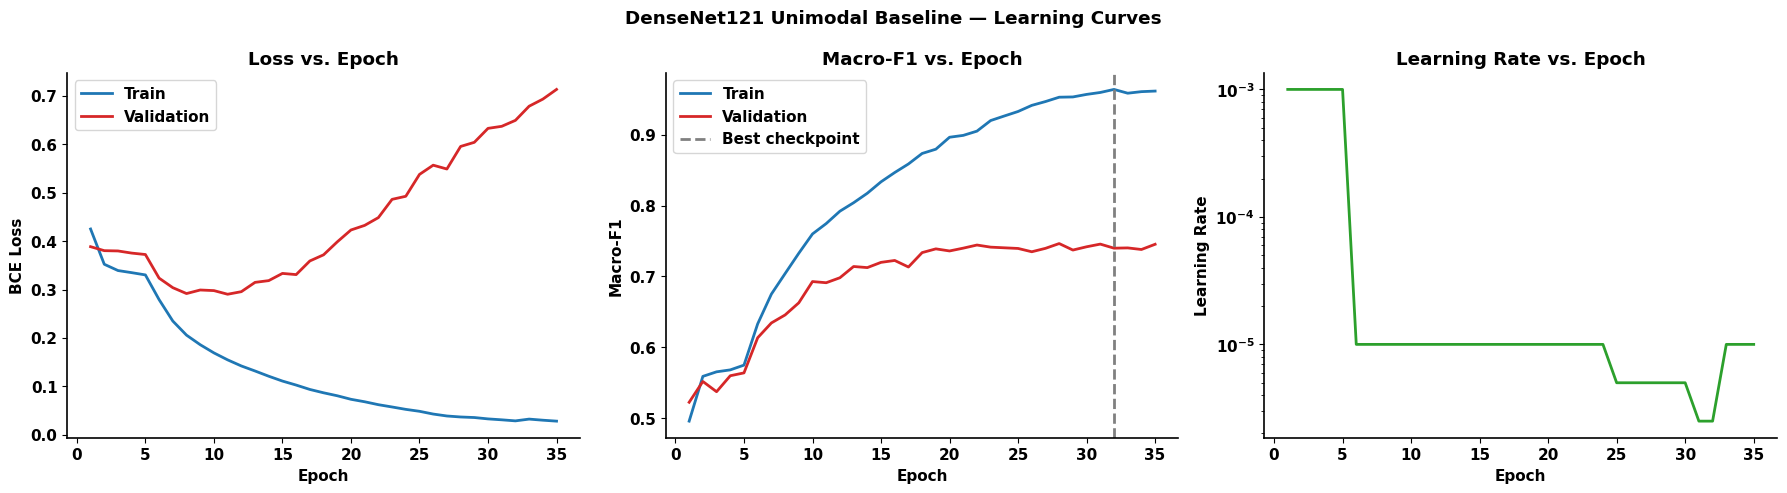

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/figures/learning_curves.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/figures/learning_curves_300dpi.png


In [19]:
# ============================================================
# CELL 18 — LEARNING CURVES FIGURE
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 11, "axes.linewidth": 1.2, "lines.linewidth": 2.0,
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(training_history_df["Epoch"], training_history_df["Train_Loss"], label="Train", color="#1f77b4")
axes[0].plot(training_history_df["Epoch"], training_history_df["Val_Loss"], label="Validation", color="#d62728")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].set_title("Loss vs. Epoch")
axes[0].legend(frameon=True)

axes[1].plot(training_history_df["Epoch"], training_history_df["Train_Macro_F1"], label="Train", color="#1f77b4")
axes[1].plot(training_history_df["Epoch"], training_history_df["Val_Macro_F1"], label="Validation", color="#d62728")
axes[1].axvline(best_epoch_info["epoch"], color="gray", linestyle="--", label="Best checkpoint")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Macro-F1"); axes[1].set_title("Macro-F1 vs. Epoch")
axes[1].legend(frameon=True)

axes[2].plot(training_history_df["Epoch"], training_history_df["Learning_Rate"], color="#2ca02c")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Learning Rate"); axes[2].set_title("Learning Rate vs. Epoch")
axes[2].set_yscale("log")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("DenseNet121 Unimodal Baseline — Learning Curves", fontweight="bold")
fig.tight_layout()
fig.savefig(LEARNING_CURVES_PDF, format="pdf", bbox_inches="tight")
fig.savefig(LEARNING_CURVES_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", LEARNING_CURVES_PDF)
print("Saved:", LEARNING_CURVES_PNG)


## 18. Full multi-label evaluation function (Part 12)

Computes every overall and per-label metric requested, handling labels with
insufficient positive/negative support **safely** — reported as `NaN` with
an explicit reason, never silently dropped.

In [21]:
# ============================================================
# CELL 19 — FULL MULTI-LABEL EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    precision_recall_fscore_support, roc_auc_score, average_precision_score,
    hamming_loss, accuracy_score, multilabel_confusion_matrix,
)

def full_multilabel_evaluation(y_true, y_score, threshold, label_names):
    y_pred = (y_score >= threshold).astype(int)
    n_labels = y_true.shape[1]

    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0)

    per_label_p, per_label_r, per_label_f1, per_label_support = precision_recall_fscore_support(
        y_true, y_pred, average=None, zero_division=0)

    hamming = hamming_loss(y_true, y_pred)
    subset_acc = accuracy_score(y_true, y_pred)  # exact-match ratio for multilabel indicator input

    per_label_roc_auc, per_label_pr_auc = [], []
    for c in range(n_labels):
        col_true = y_true[:, c]
        if len(np.unique(col_true)) < 2:
            per_label_roc_auc.append(np.nan)
            per_label_pr_auc.append(np.nan)
            continue
        per_label_roc_auc.append(roc_auc_score(col_true, y_score[:, c]))
        per_label_pr_auc.append(average_precision_score(col_true, y_score[:, c]))

    degenerate_labels = [label_names[c] for c in range(n_labels) if np.isnan(per_label_roc_auc[c])]

    try:
        micro_roc_auc = roc_auc_score(y_true, y_score, average="micro")
    except ValueError:
        micro_roc_auc = np.nan
    macro_roc_auc = float(np.nanmean(per_label_roc_auc)) if not all(np.isnan(per_label_roc_auc)) else np.nan

    try:
        micro_pr_auc = average_precision_score(y_true, y_score, average="micro")
    except ValueError:
        micro_pr_auc = np.nan
    macro_pr_auc = float(np.nanmean(per_label_pr_auc)) if not all(np.isnan(per_label_pr_auc)) else np.nan

    overall = {
        "Micro_Precision": micro_p, "Micro_Recall": micro_r, "Micro_F1": micro_f1,
        "Macro_Precision": macro_p, "Macro_Recall": macro_r, "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1, "Hamming_Loss": hamming, "Subset_Accuracy": subset_acc,
        "ROC_AUC_Micro": micro_roc_auc, "ROC_AUC_Macro": macro_roc_auc,
        "PR_AUC_Micro": micro_pr_auc, "PR_AUC_Macro": macro_pr_auc,
        "N_Samples": int(y_true.shape[0]), "Threshold": threshold,
        "Labels_With_Insufficient_Support": ", ".join(degenerate_labels) if degenerate_labels else "none",
    }

    per_label = pd.DataFrame({
        "Label_Name": label_names,
        "Precision": per_label_p, "Recall": per_label_r, "F1": per_label_f1,
        "Support": per_label_support, "ROC_AUC": per_label_roc_auc, "PR_AUC": per_label_pr_auc,
    })

    return overall, per_label, y_pred

print("full_multilabel_evaluation() defined — reports, never silently drops, degenerate labels.")


full_multilabel_evaluation() defined — reports, never silently drops, degenerate labels.


## 19. Load the best checkpoint and evaluate on Validation

This is a development-time report (Validation was already used for early
stopping / checkpoint selection) — it is not the final result.

In [22]:
# ============================================================
# CELL 20 — LOAD BEST CHECKPOINT, EVALUATE ON VALIDATION
# ============================================================

best_checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
densenet.load_state_dict(best_checkpoint["model_state_dict"])
densenet.eval()

print(f"Loaded best checkpoint: epoch={best_checkpoint['epoch']}, stage={best_checkpoint['stage']}, "
      f"validation_macro_f1={best_checkpoint['validation_macro_f1']:.4f}")

_, _, val_y_true, val_y_score, val_ids = evaluate_epoch(densenet, dataloaders["validation"])
val_overall, val_per_label, val_y_pred = full_multilabel_evaluation(
    val_y_true, val_y_score, TRAINING_CONFIG["decision_threshold"], LABEL_NAMES,
)
val_per_label.insert(0, "Split", "validation")

val_metrics_df = pd.DataFrame([val_overall])
safe_save_csv(VAL_METRICS_PATH, val_metrics_df)

print("\nVALIDATION METRICS (development-time; not the final result):")
display(val_metrics_df)


Loaded best checkpoint: epoch=28, stage=2, validation_macro_f1=0.7465
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/densenet121_validation_metrics.csv

VALIDATION METRICS (development-time; not the final result):


,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,PR_AUC_Micro,PR_AUC_Macro,N_Samples,Threshold,Labels_With_Insufficient_Support
0,0.839739,0.881992,0.860347,0.742266,0.769649,0.746472,0.861967,0.025082,0.688257,0.986477,0.967072,0.932007,0.792732,9819,0.5,none


## 20. FINAL TEST EVALUATION (Part 14, Part 23)

Only now, after every training/architecture/threshold decision is frozen,
is Test loaded for evaluation. Test is never used to pick epochs,
checkpoints, hyperparameters, augmentation, architecture, or the decision
threshold.

In [23]:
# ============================================================
# CELL 21 — FINAL TEST EVALUATION (TEST TOUCHED HERE ONLY)
# ============================================================

print("=" * 80)
print("FINAL TEST EVALUATION — TEST SET TOUCHED FOR THE FIRST AND ONLY TIME HERE")
print("=" * 80)

_, _, test_y_true, test_y_score, test_ids = evaluate_epoch(densenet, dataloaders["test"])
test_overall, test_per_label, test_y_pred = full_multilabel_evaluation(
    test_y_true, test_y_score, TRAINING_CONFIG["decision_threshold"], LABEL_NAMES,
)
test_per_label.insert(0, "Split", "test")

test_metrics_df = pd.DataFrame([test_overall])
safe_save_csv(TEST_METRICS_PATH, test_metrics_df)

per_label_metrics_df = pd.concat([val_per_label, test_per_label], ignore_index=True)
safe_save_csv(PER_LABEL_METRICS_PATH, per_label_metrics_df)

print("\nFINAL TEST RESULTS:")
display(test_metrics_df)
print("\nPer-label results (Validation + Test):")
display(per_label_metrics_df)


FINAL TEST EVALUATION — TEST SET TOUCHED FOR THE FIRST AND ONLY TIME HERE
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/densenet121_test_metrics.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/densenet121_per_label_metrics.csv

FINAL TEST RESULTS:


,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,PR_AUC_Micro,PR_AUC_Macro,N_Samples,Threshold,Labels_With_Insufficient_Support
0,0.848784,0.886673,0.867315,0.74615,0.784097,0.758081,0.867706,0.02381,0.697872,0.986923,0.963388,0.934676,0.802742,9870,0.5,none



Per-label results (Validation + Test):


,Split,Label_Name,Precision,Recall,F1,Support,ROC_AUC,PR_AUC
0,validation,Abdomen,0.459048,0.445471,0.452158,541,0.859496,0.479979
1,validation,Angiogram,0.637084,0.954869,0.764259,421,0.989921,0.796840
2,validation,Breast,0.586207,0.425000,0.492754,40,0.971824,0.509331
3,validation,Lower Extremity,0.812500,0.892449,0.850600,437,0.989079,0.907851
4,validation,Magnetic Resonance Imaging,0.848943,0.969634,0.905284,1449,0.995680,0.977736
5,validation,Pelvis,0.389706,0.341935,0.364261,465,0.841131,0.372368
6,validation,Positron-Emission Tomography,0.812500,0.942029,0.872483,69,0.993417,0.910552
7,validation,Bone structure of cranium,0.887805,0.921519,0.904348,395,0.980004,0.946008
8,validation,Vertebral column,0.662651,0.597826,0.628571,184,0.945905,0.636847
9,validation,X-Ray Computed Tomography,0.980732,0.953829,0.967093,3682,0.996725,0.994367


## 21. Save predictions

In [24]:
# ============================================================
# CELL 22 — SAVE PREDICTIONS (VALIDATION + TEST)
# ============================================================

def build_predictions_df(split_name, ids, y_true, y_score, y_pred):
    rows = {"ID": ids, "Split": split_name}
    for i, col in enumerate(LABEL_COLUMNS):
        rows[f"{col}_true"] = y_true[:, i]
        rows[f"{col}_prob"] = y_score[:, i]
        rows[f"{col}_pred"] = y_pred[:, i]
    return pd.DataFrame(rows)

# IDs come from evaluate_epoch's own loop (Cells 20/21) — NOT re-fetched from
# split_dfs — because the Dataset's retry-on-corrupt-sample logic (Cell 6)
# can substitute a different sample at a given position, which would silently
# break a naive "same row order as the source CSV" assumption.
assert len(val_ids) == len(val_y_true), "val_ids length must match val_y_true rows."
assert len(test_ids) == len(test_y_true), "test_ids length must match test_y_true rows."

predictions_df = pd.concat([
    build_predictions_df("validation", val_ids, val_y_true, val_y_score, val_y_pred),
    build_predictions_df("test", test_ids, test_y_true, test_y_score, test_y_pred),
], ignore_index=True)

safe_save_csv(PREDICTIONS_PATH, predictions_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/densenet121_predictions.csv


## 22. Publication-quality ROC curves (Part 16) — Test set

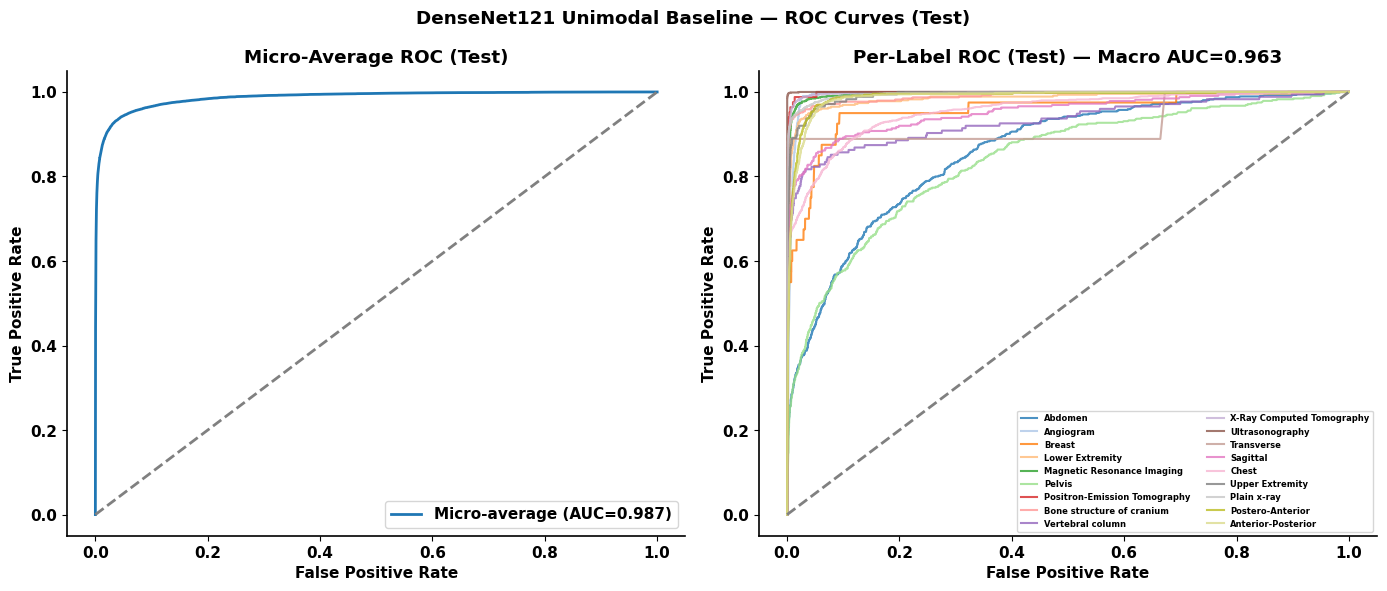

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/figures/roc_curves.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/figures/roc_curves_300dpi.png


In [25]:
# ============================================================
# CELL 23 — ROC CURVES FIGURE (TEST)
# ============================================================

from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

fpr_micro, tpr_micro, _ = roc_curve(test_y_true.ravel(), test_y_score.ravel())
axes[0].plot(fpr_micro, tpr_micro, color="#1f77b4",
             label=f"Micro-average (AUC={test_overall['ROC_AUC_Micro']:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Micro-Average ROC (Test)"); axes[0].legend(frameon=True)

cmap = plt.get_cmap("tab20")
for c in range(N_LABELS):
    if len(np.unique(test_y_true[:, c])) < 2:
        continue
    fpr_c, tpr_c, _ = roc_curve(test_y_true[:, c], test_y_score[:, c])
    axes[1].plot(fpr_c, tpr_c, color=cmap(c % 20), alpha=0.8, linewidth=1.5, label=LABEL_NAMES[c])
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title(f"Per-Label ROC (Test) — Macro AUC={test_overall['ROC_AUC_Macro']:.3f}")
axes[1].legend(fontsize=6, ncol=2, frameon=True, loc="lower right")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("DenseNet121 Unimodal Baseline — ROC Curves (Test)", fontweight="bold")
fig.tight_layout()
fig.savefig(ROC_CURVES_PDF, format="pdf", bbox_inches="tight")
fig.savefig(ROC_CURVES_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", ROC_CURVES_PDF)
print("Saved:", ROC_CURVES_PNG)


## 23. Publication-quality Precision-Recall curves (Part 17) — Test set

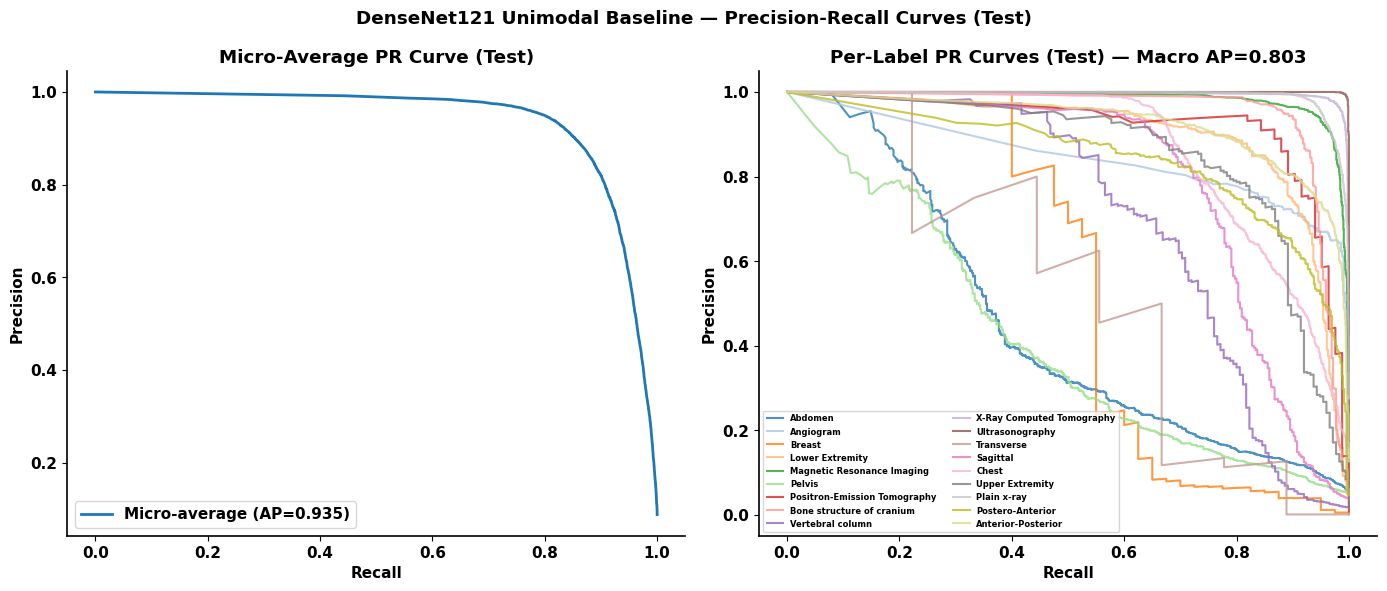

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/figures/precision_recall_curves.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/figures/precision_recall_curves_300dpi.png


In [26]:
# ============================================================
# CELL 24 — PRECISION-RECALL CURVES FIGURE (TEST)
# ============================================================

from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

prec_micro, rec_micro, _ = precision_recall_curve(test_y_true.ravel(), test_y_score.ravel())
axes[0].plot(rec_micro, prec_micro, color="#1f77b4",
             label=f"Micro-average (AP={test_overall['PR_AUC_Micro']:.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision")
axes[0].set_title("Micro-Average PR Curve (Test)"); axes[0].legend(frameon=True)

for c in range(N_LABELS):
    if len(np.unique(test_y_true[:, c])) < 2:
        continue
    prec_c, rec_c, _ = precision_recall_curve(test_y_true[:, c], test_y_score[:, c])
    axes[1].plot(rec_c, prec_c, color=cmap(c % 20), alpha=0.8, linewidth=1.5, label=LABEL_NAMES[c])
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title(f"Per-Label PR Curves (Test) — Macro AP={test_overall['PR_AUC_Macro']:.3f}")
axes[1].legend(fontsize=6, ncol=2, frameon=True, loc="lower left")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("DenseNet121 Unimodal Baseline — Precision-Recall Curves (Test)", fontweight="bold")
fig.tight_layout()
fig.savefig(PR_CURVES_PDF, format="pdf", bbox_inches="tight")
fig.savefig(PR_CURVES_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", PR_CURVES_PDF)
print("Saved:", PR_CURVES_PNG)


## 24. Multi-label confusion matrices (Part 18) — one 2x2 per label, Test set

Not a single 18-class confusion matrix (that would misrepresent a
multi-label problem as multiclass) — eighteen independent 2x2 matrices.

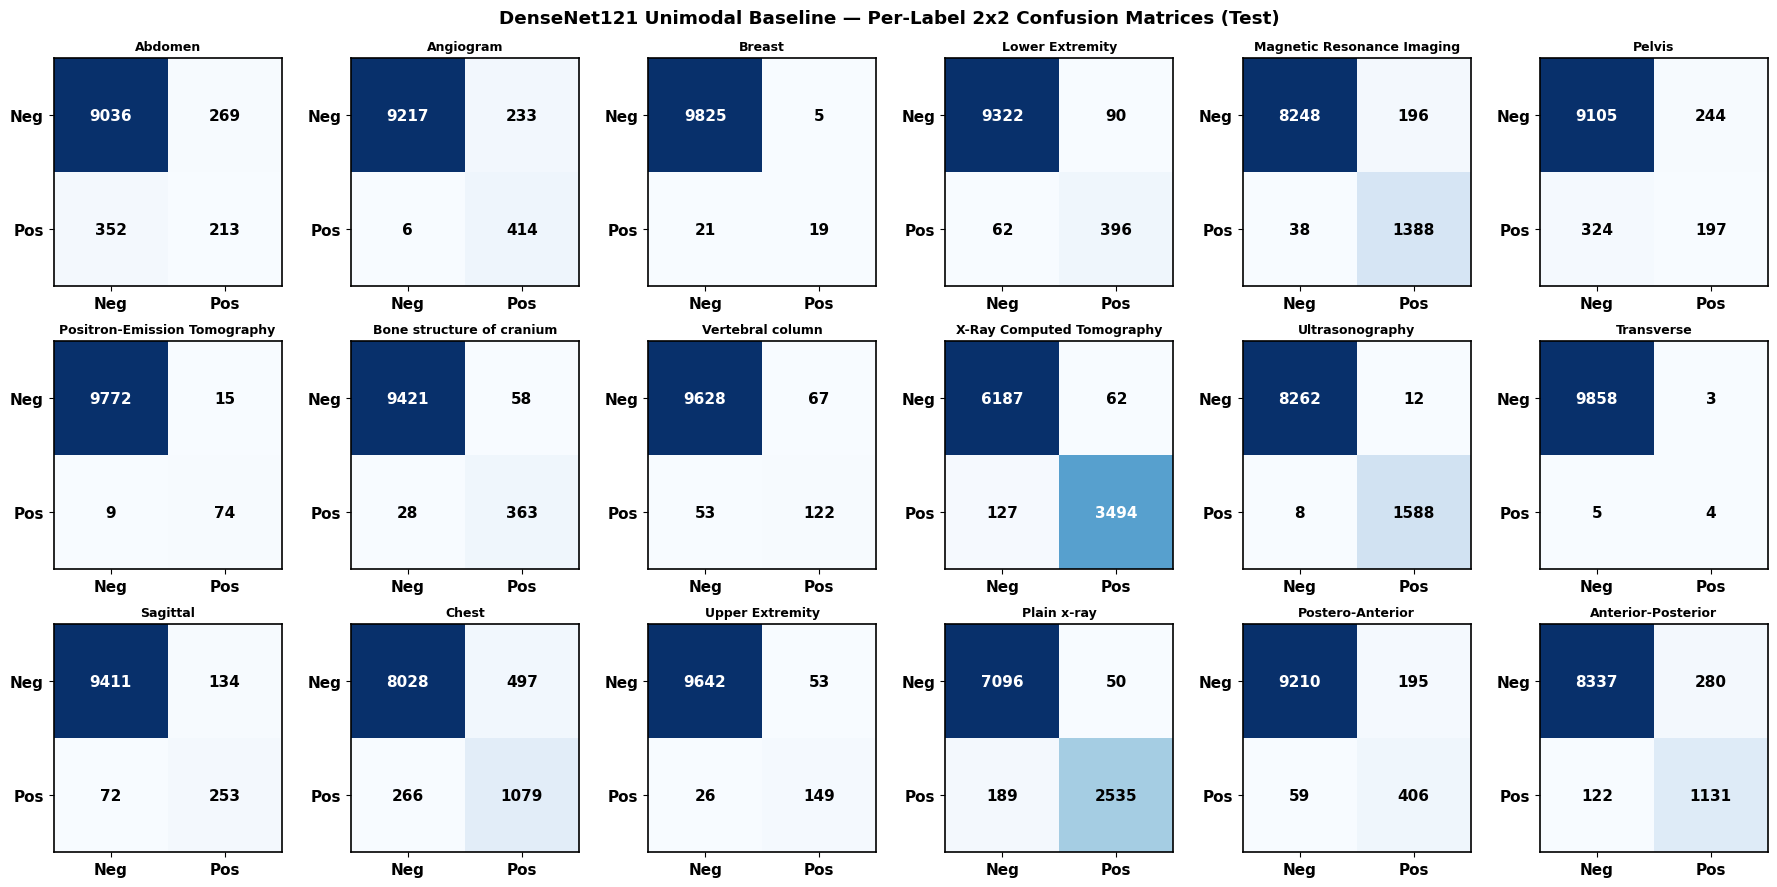

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/figures/multilabel_confusion_matrices.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/figures/multilabel_confusion_matrices_300dpi.png


In [27]:
# ============================================================
# CELL 25 — MULTI-LABEL CONFUSION MATRICES FIGURE (TEST)
# ============================================================

cm_array = multilabel_confusion_matrix(test_y_true, test_y_pred)  # shape (18, 2, 2)

n_cols = 6
n_rows = int(np.ceil(N_LABELS / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 3 * n_rows))
axes = axes.flatten()

for c in range(N_LABELS):
    ax = axes[c]
    cm = cm_array[c]
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Neg", "Pos"]); ax.set_yticklabels(["Neg", "Pos"])
    ax.set_title(LABEL_NAMES[c], fontsize=9)

for c in range(N_LABELS, len(axes)):
    axes[c].axis("off")

fig.suptitle("DenseNet121 Unimodal Baseline — Per-Label 2x2 Confusion Matrices (Test)", fontweight="bold")
fig.tight_layout()
fig.savefig(CM_PDF, format="pdf", bbox_inches="tight")
fig.savefig(CM_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", CM_PDF)
print("Saved:", CM_PNG)


## 25. Model diagnostics (Part 19)

Overfitting is assessed from the actual train/validation loss and Macro-F1
gap recorded in training history — not asserted.

In [28]:
# ============================================================
# CELL 26 — MODEL DIAGNOSTICS
# ============================================================

final_row = training_history_df.iloc[-1]
best_row = training_history_df.loc[training_history_df["Epoch"] == best_epoch_info["epoch"]].iloc[0]

loss_gap = final_row["Train_Loss"] - final_row["Val_Loss"]
f1_gap = final_row["Train_Macro_F1"] - final_row["Val_Macro_F1"]

if f1_gap > 0.15:
    fit_diagnosis = "possible overfitting (large train/validation Macro-F1 gap)"
elif final_row["Train_Macro_F1"] < 0.3 and final_row["Val_Macro_F1"] < 0.3:
    fit_diagnosis = "possible underfitting (both train and validation Macro-F1 remain low)"
else:
    fit_diagnosis = "reasonably well-fitted (no large train/validation gap observed)"

print("=" * 80)
print("MODEL DIAGNOSTICS")
print("=" * 80)
print(f"Final train loss: {final_row['Train_Loss']:.4f} | Final val loss: {final_row['Val_Loss']:.4f}")
print(f"Final train Macro-F1: {final_row['Train_Macro_F1']:.4f} | Final val Macro-F1: {final_row['Val_Macro_F1']:.4f}")
print(f"Best epoch: {best_epoch_info['epoch']} (stage {best_epoch_info['stage']}), "
      f"best val Macro-F1: {best_epoch_info['val_macro_f1']:.4f}")
print(f"Total epochs run: {global_epoch} | Training duration: {total_training_seconds/60:.1f} min")
print(f"Total parameters: {total_params:,}")
print(f"\nTrain-Val loss gap (final epoch): {loss_gap:.4f}")
print(f"Train-Val Macro-F1 gap (final epoch): {f1_gap:.4f}")
print(f"\nDiagnosis (derived from the numbers above, not asserted): {fit_diagnosis}")


MODEL DIAGNOSTICS
Final train loss: 0.0283 | Final val loss: 0.7130
Final train Macro-F1: 0.9617 | Final val Macro-F1: 0.7455
Best epoch: 32 (stage 2), best val Macro-F1: 0.7400
Total epochs run: 35 | Training duration: 35.0 min
Total parameters: 6,972,306

Train-Val loss gap (final epoch): -0.6847
Train-Val Macro-F1 gap (final epoch): 0.2162

Diagnosis (derived from the numbers above, not asserted): possible overfitting (large train/validation Macro-F1 gap)


## 26. Reproducibility record (Part 20)

In [29]:
# ============================================================
# CELL 27 — REPRODUCIBILITY.JSON
# ============================================================

def package_version(module_name):
    try:
        module = __import__(module_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not installed"

reproducibility = {
    "notebook": "05_ROCOv2_Unimodal_DenseNet121_Baseline",
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "torchvision_version": package_version("torchvision"),
    "sklearn_version": package_version("sklearn"),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "mixed_precision_enabled": AMP_ENABLED,
    "random_seed": SEED,
    "densenet121_pretrained_weights": PRETRAINED_WEIGHTS_NAME,
    "preprocessing_config_source": str(PREPROCESSING_CONFIG_PATH),
    "dataset_source": str(PREPARED_DIR),
    "training_config": TRAINING_CONFIG,
    "best_epoch": best_epoch_info,
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/reproducibility.json


## 27. Calibration warning (Part 24) — read before touching Notebook 06/07

**Explicit methodological note.** This must not be glossed over.

In [30]:
# ============================================================
# CELL 28 — CALIBRATION STATUS WARNING
# ============================================================

print("=" * 80)
print("CALIBRATION STATUS — READ BEFORE PROCEEDING TO CONFORMAL PREDICTION")
print("=" * 80)
print('''
Current dataset: Train / Validation / Test only.
There is currently NO independent Calibration split.

Validation in THIS notebook was used for:
  - early stopping
  - best-checkpoint selection
  - model-development decisions

Therefore Validation should NOT automatically be treated as an independent
Conformal Prediction calibration set — it has already been used extensively
for model development, which would bias conformal coverage guarantees if
reused naively for calibration.

No Calibration split is created in this notebook.

Recommendation for the Conformal Prediction notebook (07): establish a
proper calibration strategy before running any conformal experiments, e.g.
  (A) an independent Calibration subset carved from data that has NOT been
      used to train or select this final model, or
  (B) another scientifically justified calibration strategy.
Neither strategy is implemented here — that decision belongs to Notebook 07.
''')


CALIBRATION STATUS — READ BEFORE PROCEEDING TO CONFORMAL PREDICTION

Current dataset: Train / Validation / Test only.
There is currently NO independent Calibration split.

Validation in THIS notebook was used for:
  - early stopping
  - best-checkpoint selection
  - model-development decisions

Therefore Validation should NOT automatically be treated as an independent
Conformal Prediction calibration set — it has already been used extensively
for model development, which would bias conformal coverage guarantees if
reused naively for calibration.

No Calibration split is created in this notebook.

Recommendation for the Conformal Prediction notebook (07): establish a
proper calibration strategy before running any conformal experiments, e.g.
  (A) an independent Calibration subset carved from data that has NOT been
      used to train or select this final model, or
  (B) another scientifically justified calibration strategy.
Neither strategy is implemented here — that decision belongs to

## 28. Artifact manifest and final report (Part 22, Part 25)

In [31]:
# ============================================================
# CELL 29 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    CONFIG_PATH, HISTORY_PATH, VAL_METRICS_PATH, TEST_METRICS_PATH, PER_LABEL_METRICS_PATH,
    PREDICTIONS_PATH, BEST_MODEL_PATH, LAST_MODEL_PATH,
    LEARNING_CURVES_PDF, LEARNING_CURVES_PNG, ROC_CURVES_PDF, ROC_CURVES_PNG,
    PR_CURVES_PDF, PR_CURVES_PNG, CM_PDF, CM_PNG, REPRODUCIBILITY_PATH,
]

manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"

# ------------------------------------------------------------
# Corrupt-sample transparency check (Cell 6) — supplementary, not one of
# the 18 required artifacts, but never omitted from the report if non-empty.
# ------------------------------------------------------------
if CORRUPT_SAMPLE_LOG_PATH.exists():
    corrupt_log_df = pd.read_json(CORRUPT_SAMPLE_LOG_PATH, lines=True)
    n_corrupt_skipped = len(corrupt_log_df)
    corrupt_by_split = corrupt_log_df.groupby("Split")["ID"].nunique().to_dict()
else:
    corrupt_log_df = pd.DataFrame()
    n_corrupt_skipped = 0
    corrupt_by_split = {}

print(f"\nSamples skipped during training/evaluation (unreadable even after the "
      f"'unzip' fallback): {n_corrupt_skipped}")
if n_corrupt_skipped:
    print(f"  By split: {corrupt_by_split}")
    print(f"  Full detail: {CORRUPT_SAMPLE_LOG_PATH}")
    display(corrupt_log_df)

manifest.append({
    "Artifact": CORRUPT_SAMPLE_LOG_PATH.name, "Path": str(CORRUPT_SAMPLE_LOG_PATH),
    "Exists": CORRUPT_SAMPLE_LOG_PATH.exists(),
    "Size_KB": round(CORRUPT_SAMPLE_LOG_PATH.stat().st_size / 1024, 2) if CORRUPT_SAMPLE_LOG_PATH.exists() else None,
    "Note": "Supplementary — not one of the 18 required artifacts. Present only if a sample "
            "was unreadable even after the zip fallback.",
})

safe_save_json(MANIFEST_PATH, {
    "artifacts": manifest, "status": notebook_status,
    "corrupt_samples_skipped_during_training": n_corrupt_skipped,
    "corrupt_samples_by_split": corrupt_by_split,
})

# ------------------------------------------------------------
# Data-leakage self-check (evidence-based, not asserted)
# ------------------------------------------------------------
train_ids = set(split_dfs["train"]["ID"].astype(str))
val_ids = set(split_dfs["validation"]["ID"].astype(str))
test_ids = set(split_dfs["test"]["ID"].astype(str))
train_test_overlap = train_ids & test_ids
val_test_overlap = val_ids & test_ids

print("\n" + "=" * 60)
print("ROCOv2 DENSENET121 UNIMODAL BASELINE")
print("FINAL REPORT")
print("=" * 60)

print(f'''
Dataset:
ROCOv2

Total samples:

Train:
{len(split_dfs['train']):,}
Validation:
{len(split_dfs['validation']):,}
Test:
{len(split_dfs['test']):,}

Number of labels:
{N_LABELS}

Task:
Multi-label classification

Model:
DenseNet121

Pretrained:
{"YES" if PRETRAINED else "NO"}

Input image size:
{IMAGE_SIZE}

Loss:
BCEWithLogitsLoss (pos_weight, Train-only, capped at {TRAINING_CONFIG['pos_weight_cap']})

Optimizer:
{TRAINING_CONFIG['optimizer']}

Learning rate:
Stage 1: {TRAINING_CONFIG['stage1_lr']} | Stage 2: {TRAINING_CONFIG['stage2_lr']}

Batch size:
{TRAINING_CONFIG['batch_size']}

Epochs:
{global_epoch} (stage 1 max {TRAINING_CONFIG['stage1_max_epochs']}, stage 2 max {TRAINING_CONFIG['stage2_max_epochs']})

Early stopping metric:
{TRAINING_CONFIG['early_stopping_metric']}

Best epoch:
{best_epoch_info['epoch']} (stage {best_epoch_info['stage']})

Best validation Macro-F1:
{best_val_macro_f1:.4f}

------------------------------------------------------------
FINAL TEST RESULTS
------------------------------------------------------------

Micro Precision:
{test_overall['Micro_Precision']:.4f}
Micro Recall:
{test_overall['Micro_Recall']:.4f}
Micro F1:
{test_overall['Micro_F1']:.4f}

Macro Precision:
{test_overall['Macro_Precision']:.4f}
Macro Recall:
{test_overall['Macro_Recall']:.4f}
Macro F1:
{test_overall['Macro_F1']:.4f}

Micro ROC-AUC:
{test_overall['ROC_AUC_Micro']:.4f}
Macro ROC-AUC:
{test_overall['ROC_AUC_Macro']:.4f}

Micro PR-AUC:
{test_overall['PR_AUC_Micro']:.4f}
Macro PR-AUC:
{test_overall['PR_AUC_Macro']:.4f}

Hamming Loss:
{test_overall['Hamming_Loss']:.4f}
Subset Accuracy:
{test_overall['Subset_Accuracy']:.4f}

------------------------------------------------------------
CALIBRATION STATUS
------------------------------------------------------------

Separate Calibration set currently exists:
NO

Current Validation role:
Early stopping / model development

Test role:
Final evaluation only

Conformal calibration:
NOT IMPLEMENTED IN THIS NOTEBOOK

------------------------------------------------------------
DATA LEAKAGE
------------------------------------------------------------

Train/Test overlap:
{"PASS" if not train_test_overlap else "FAIL — " + str(len(train_test_overlap)) + " shared IDs"}

Validation/Test overlap:
{"PASS" if not val_test_overlap else "FAIL — " + str(len(val_test_overlap)) + " shared IDs"}

Test used during training:
NO

Test used for model selection:
NO

Test used for threshold optimization:
NO

------------------------------------------------------------
DATA INTEGRITY (archive-level)
------------------------------------------------------------

Samples unreadable even after zip fallback (skipped, logged, not silently dropped):
{n_corrupt_skipped} ({corrupt_by_split if corrupt_by_split else 'none'})

------------------------------------------------------------
PUBLICATION FIGURES
------------------------------------------------------------

Vector PDF:
YES

300-DPI PNG:
YES

Bold/readable typography:
YES

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

DenseNet121 image-only baseline:
{"COMPLETE" if not manifest_missing else "NOT READY"}

Dataset modified:
NO

Previous notebooks modified:
NO

Calibration split created:
NO

Ready for VLM baseline:
{"YES" if not manifest_missing else "NO"}
''')
print("=" * 60)

assert not train_test_overlap, "Train/Test ID overlap detected — this must never happen."
assert not val_test_overlap, "Validation/Test ID overlap detected — this must never happen."

print("\nSTOP — Notebook 05 (DenseNet121 unimodal baseline) is complete.")
print("Not implemented here (by design): VLM, VLM training, Conformal Prediction,")
print("Calibration split, Counterfactual Explanations, XAI, Trust Score.")
print("Next notebook: 06_ROCOv2_VLM_Baseline.ipynb")


,Artifact,Path,Exists,Size_KB
0,densenet121_config.json,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,10.34
1,densenet121_training_history.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,3.85
2,densenet121_validation_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,0.48
3,densenet121_test_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,0.47
4,densenet121_per_label_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,4.27
5,densenet121_predictions.csv,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,5615.22
6,densenet121_best_model.pt,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,27839.07
7,densenet121_last_model.pt,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,27839.07
8,learning_curves.pdf,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,19.56
9,learning_curves_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/Baselin...,True,288.13



Samples skipped during training/evaluation (unreadable even after the 'unzip' fallback): 0
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Baselines/DenseNet121_Unimodal_seed123/artifact_manifest.json

ROCOv2 DENSENET121 UNIMODAL BASELINE
FINAL REPORT

Dataset:
ROCOv2

Total samples:

Train:
59,666
Validation:
9,819
Test:
9,870

Number of labels:
18

Task:
Multi-label classification

Model:
DenseNet121

Pretrained:
YES

Input image size:
224

Loss:
BCEWithLogitsLoss (pos_weight, Train-only, capped at 20.0)

Optimizer:
AdamW

Learning rate:
Stage 1: 0.001 | Stage 2: 1e-05

Batch size:
32

Epochs:
35 (stage 1 max 5, stage 2 max 30)

Early stopping metric:
validation_macro_f1

Best epoch:
32 (stage 2)

Best validation Macro-F1:
0.7400

------------------------------------------------------------
FINAL TEST RESULTS
------------------------------------------------------------

Micro Precision:
0.8488
Micro Recall:
0.8867
Micro F1:
0.8673

Macro Precision:
0.7462
Macro Recall:
0.7841
Macro F1